# Paywall redesign A/B test

FormWise is a made-up online legal-document subscription service. The data is simulated (see `data/generate_data.py`).

Users fill in a document and then hit a paywall before they can download it. The product team built a new paywall
that shows a preview of the finished document and a side-by-side comparison of the monthly and annual plans.
The question: does it convert more people, and should we ship it?

### Test plan (agreed before launch)

| | |
|---|---|
| Randomization | visitor level, 50/50 at first visit |
| Analysis population | visitors who actually saw the paywall |
| Primary metric | paywall to purchase conversion |
| Secondary metric | revenue per paywall viewer (first payment) |
| Guardrail | share of buyers choosing the annual plan should not drop |
| Alpha / power | 0.05 two-sided, 80% |
| Minimum detectable effect | +15% relative |
| Dates | Apr 6 to Jun 14, 2026 (10 weeks, from the sample size calc below) |

Purchases are counted from billing data, not the front-end `purchase` event. One mobile app release during the
test sent purchase events without a user ID, so event-based counts would undercount mobile buyers.

In [1]:
import os, sys, sqlite3, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB = "data/formwise.db"
if not os.path.exists(DB):
    subprocess.run([sys.executable, "data/generate_data.py"], check=True)
con = sqlite3.connect(DB)

def q(sql):
    if sql.endswith(".sql"):
        sql = open(sql).read()
    return pd.read_sql_query(sql, con)

BLUE, ORANGE, GREY = "#2B5C8A", "#D9822B", "#9AA5B1"
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
os.makedirs("figures", exist_ok=True)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

## 1. Sample size
Baseline conversion from the 8 weeks before the test.

In [2]:
baseline = q("""
WITH pv AS (
  SELECT DISTINCT visitor_id FROM events
  WHERE event_name = 'paywall_view'
    AND event_ts >= '2026-02-09' AND event_ts < '2026-04-06')
SELECT COUNT(*) AS paywall_viewers,
       SUM(CASE WHEN s.user_id IS NOT NULL THEN 1 ELSE 0 END) AS purchasers
FROM pv LEFT JOIN subscriptions s ON s.visitor_id = pv.visitor_id
""")
p0 = baseline.purchasers[0] / baseline.paywall_viewers[0]
weekly_viewers = baseline.paywall_viewers[0] / 8
p1 = p0 * 1.15
n_per_arm = NormalIndPower().solve_power(proportion_effectsize(p1, p0), alpha=0.05, power=0.8, ratio=1)
print(f"Baseline conversion: {p0:.2%}   target: {p1:.2%}")
print(f"Needed: {n_per_arm:,.0f} paywall viewers per arm")
print(f"Paywall viewers per week: {weekly_viewers:,.0f}, so about {2*n_per_arm/weekly_viewers:.1f} weeks")

Baseline conversion: 18.80%   target: 21.62%
Needed: 3,179 paywall viewers per arm
Paywall viewers per week: 673, so about 9.5 weeks


About 9.5 weeks, so the test ran for 10 full weeks and was only analysed at the end. No peeking.

## 2. Sanity checks
**Sample ratio mismatch.** If the split isn't close to 50/50, something in assignment is broken and the results
can't be trusted.

In [3]:
assign = q("SELECT variant, COUNT(*) AS n FROM experiment_assignments GROUP BY variant")
chi2, p_srm = stats.chisquare(assign.n)
print(assign.to_string(index=False))
print(f"SRM chi-square p = {p_srm:.3f} ({'ok' if p_srm > 0.01 else 'investigate'})")

  variant     n
  control 13645
treatment 13849
SRM chi-square p = 0.219 (ok)


**Paywall exposure.** The change only affects the paywall itself, so the share of visitors who reach it should be
the same in both groups.

In [4]:
df = q("""
SELECT a.visitor_id, a.variant, v.device, v.channel,
       MAX(CASE WHEN e.event_name = 'paywall_view' THEN 1 ELSE 0 END) AS saw_paywall,
       s.plan, s.user_id IS NOT NULL AS purchased,
       COALESCE(p.amount, 0) AS first_payment
FROM experiment_assignments a
JOIN visitors v ON v.visitor_id = a.visitor_id
LEFT JOIN events e ON e.visitor_id = a.visitor_id AND e.event_name = 'paywall_view'
LEFT JOIN subscriptions s ON s.visitor_id = a.visitor_id
LEFT JOIN payments p ON p.user_id = s.user_id AND p.payment_type = 'new'
GROUP BY a.visitor_id
""")
reach = df.groupby("variant").saw_paywall.agg(["sum", "count", "mean"])
z, p_reach = proportions_ztest(reach["sum"], reach["count"])
print(reach.rename(columns={"sum": "saw_paywall", "count": "assigned", "mean": "reach_rate"}).round(4))
print(f"Reach rate difference p = {p_reach:.3f}")

           saw_paywall  assigned  reach_rate
variant                                     
control           3538     13645      0.2593
treatment         3457     13849      0.2496
Reach rate difference p = 0.066


Both look fine.

## 3. Primary metric: paywall to purchase conversion

In [5]:
t = df[df.saw_paywall == 1]
res = t.groupby("variant").purchased.agg(purchases="sum", viewers="count")
res["conversion"] = res.purchases / res.viewers
c, tr = res.loc["control"], res.loc["treatment"]
z, p_val = proportions_ztest([tr.purchases, c.purchases], [tr.viewers, c.viewers])
lo, hi = confint_proportions_2indep(tr.purchases, tr.viewers, c.purchases, c.viewers, method="newcomb")
rel = tr.conversion / c.conversion - 1

rng = np.random.default_rng(0)
bc = rng.binomial(int(c.viewers), c.conversion, 20000) / c.viewers
bt = rng.binomial(int(tr.viewers), tr.conversion, 20000) / tr.viewers
rel_lo, rel_hi = np.percentile(bt / bc - 1, [2.5, 97.5])

print(res.round(4).to_string())
print(f"\nAbsolute lift: {tr.conversion - c.conversion:+.2%}  (95% CI {lo:+.2%} to {hi:+.2%})")
print(f"Relative lift: {rel:+.1%}  (95% CI {rel_lo:+.1%} to {rel_hi:+.1%})")
print(f"z-test p = {p_val:.4f}")

           purchases  viewers  conversion
variant                                  
control          692     3538      0.1956
treatment        723     3457      0.2091

Absolute lift: +1.36%  (95% CI -0.53% to +3.24%)
Relative lift: +6.9%  (95% CI -2.6% to +17.4%)
z-test p = 0.1584


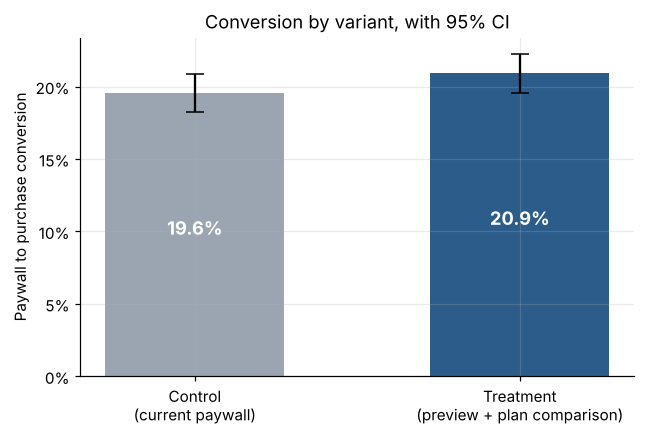

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ci = [1.96 * np.sqrt(r.conversion * (1 - r.conversion) / r.viewers) for _, r in res.iterrows()]
ax.bar(["Control\n(current paywall)", "Treatment\n(preview + plan comparison)"], res.conversion, yerr=ci,
       color=[GREY, BLUE], capsize=6, width=0.55)
for i, v_ in enumerate(res.conversion):
    ax.text(i, v_ / 2, f"{v_:.1%}", ha="center", color="white", fontweight="bold", fontsize=12)
ax.set_ylabel("Paywall to purchase conversion"); ax.yaxis.set_major_formatter(pct)
ax.set_title("Conversion by variant, with 95% CI")
fig.savefig("figures/conversion_by_variant.png", bbox_inches="tight", dpi=140); plt.show()

## 4. Secondary metric and guardrail

In [7]:
rev = t.groupby("variant").first_payment.agg(["mean", "count"])
tt = stats.ttest_ind(t[t.variant == "treatment"].first_payment, t[t.variant == "control"].first_payment, equal_var=False)
buyers = t[t.purchased == 1]
annual = buyers.groupby("variant").plan.apply(lambda s: (s == "annual").mean())
za, p_ann = proportions_ztest(
    [(buyers[buyers.variant == g].plan == "annual").sum() for g in ["treatment", "control"]],
    [(buyers.variant == g).sum() for g in ["treatment", "control"]])
print("Revenue per paywall viewer (first payment):")
print(rev["mean"].map("${:.2f}".format).to_string())
print(f"Welch t-test p = {tt.pvalue:.4f}")
print("\nAnnual plan share among buyers:")
print(annual.map("{:.1%}".format).to_string())
print(f"p = {p_ann:.3f}  ({'held' if annual['treatment'] >= annual['control'] - 0.03 else 'breached'})")

Revenue per paywall viewer (first payment):
variant
control      $12.13
treatment    $13.31
Welch t-test p = 0.0803

Annual plan share among buyers:
variant
control      39.5%
treatment    42.3%
p = 0.272  (held)


## 5. Device breakdown (exploratory)
This wasn't the main hypothesis, so I adjusted the p-values for testing three segments (Holm) and treat the
result as something to follow up on, not a conclusion.

In [8]:
rows = []
for dev, g in t.groupby("device"):
    r = g.groupby("variant").purchased.agg(["sum", "count"])
    _, p = proportions_ztest(r.loc[["treatment", "control"], "sum"], r.loc[["treatment", "control"], "count"])
    cr = r["sum"] / r["count"]
    rows.append({"device": dev, "viewers": int(r["count"].sum()), "control": cr["control"],
                 "treatment": cr["treatment"], "relative_lift": cr["treatment"] / cr["control"] - 1, "p_raw": p})
seg = pd.DataFrame(rows)
seg["p_holm"] = multipletests(seg.p_raw, method="holm")[1]
print(seg.round(4).to_string(index=False))

 device  viewers  control  treatment  relative_lift  p_raw  p_holm
desktop     4454   0.2289     0.2296         0.0029 0.9585  1.0000
 mobile     2030   0.1311     0.1699         0.2965 0.0142  0.0427
 tablet      511   0.1712     0.1811         0.0578 0.7690  1.0000


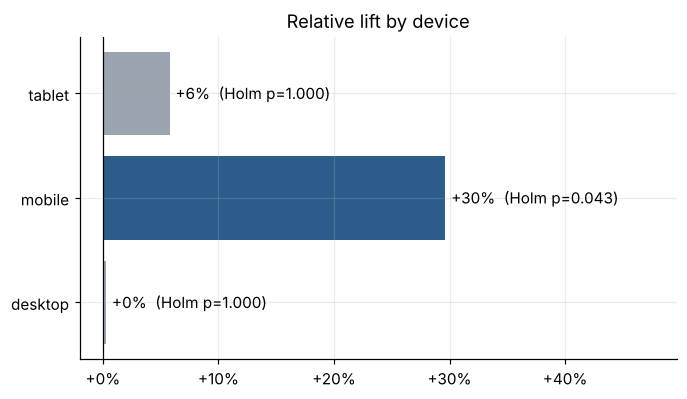

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(seg.device, seg.relative_lift, color=[BLUE if p < 0.05 else GREY for p in seg.p_holm])
for i, (l, p) in enumerate(zip(seg.relative_lift, seg.p_holm)):
    ax.text(l + 0.005, i, f"{l:+.0%}  (Holm p={p:.3f})", va="center")
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_xlim(min(0, seg.relative_lift.min()) - 0.02, seg.relative_lift.max() + 0.2)
ax.set_title("Relative lift by device")
fig.savefig("figures/lift_by_device.png", bbox_inches="tight", dpi=140); plt.show()

How long would a proper mobile-only test take?

In [10]:
m = seg.set_index("device").loc["mobile"]
n_mobile = NormalIndPower().solve_power(proportion_effectsize(m.control * 1.20, m.control), alpha=0.05, power=0.8)
mobile_weekly = t[t.device == "mobile"].shape[0] / 10
print(f"Mobile baseline {m.control:.1%}. Detecting +20% needs {n_mobile:,.0f} mobile viewers per arm.")
print(f"At ~{mobile_weekly:,.0f} mobile paywall viewers a week, that's about {2*n_mobile/mobile_weekly:.0f} weeks.")

Mobile baseline 13.1%. Detecting +20% needs 2,814 mobile viewers per arm.
At ~203 mobile paywall viewers a week, that's about 28 weeks.


## 6. Conclusion

**Overall the result is not significant.** Conversion went from 19.6% to 20.9% (+6.9% relative), but the 95% CI
runs from about -0.5 to +3.2 points and p = 0.16. The real effect is smaller than the 15% the test was sized for,
so this is "can't tell", not "doesn't work". Revenue per viewer and annual share moved the right way but neither
is significant on its own.

**Mobile looks different.** Mobile conversion went from 13.1% to 17.0% (+30%), and it holds up after the Holm
adjustment (p = 0.043). It also makes sense: on a phone, seeing the finished document is more reassuring than on
desktop, where most of the form is already visible. Desktop didn't move.

**What I'd recommend:**
1. Don't report this as an overall win.
2. For mobile, it's a trade-off. A properly sized mobile-only test would take around 28 weeks. Nothing got worse
   in the treatment group, so shipping to mobile with a 10% holdout is a reasonable option. It gets the likely gain
   sooner but with less certainty. That's a call for the product owner, so I'd present both options with their
   costs.
3. Keep the current paywall on desktop. No evidence the new one helps there.

**One thing I'd change next time:** the annual-share guardrail assumed annual subscribers are worth more. In my
retention analysis of the same data, a new monthly subscriber turned out to be worth about 2x an annual one in
first-year revenue. Expected 12-month revenue per paywall viewer would be a better guardrail.

In [11]:
con.close()